In [1]:
!pip install pdfplumber pandas matplotlib

In [2]:
import glob
import pdfplumber

files = sorted(glob.glob("data/*.pdf"))
print(len(files))

with pdfplumber.open(files[0]) as pdf:
    for i, page in enumerate(pdf.pages[:4]):
        tables = page.extract_tables()
        print(f"--- Page {i+1}: {len(tables)} table(s) ---")
        for t in tables:
            for row in t[:6]:
                print(row)

10
--- Page 1: 0 table(s) ---
--- Page 2: 0 table(s) ---
--- Page 3: 0 table(s) ---
--- Page 4: 0 table(s) ---


In [3]:
with pdfplumber.open(files[0]) as pdf:
    for i in [1, 2]:
        print(f"===== PDF page {i+1} =====")
        print(pdf.pages[i].extract_text())

===== PDF page 2 =====
Table of Contents
Overview .................................................................................................................................. 1
The Overall CPI and Inflation Trends, April 2025 – April 2026 ........................................ 1
Movement of National Average Retail Prices of Selected Commodities ............................. 6
Core and Non-Core Index and Inflation ............................................................................... 8
Contribution of Core and Non-Core to the Overall Inflation ............................................. 9
List of Tables
Table 1: One and Twelve-Month Percentage Changes in the Consumer Price Indices .... 3
Table 2: Key Drivers of Inflation for each of the 13 Divisions ............................................ 5
Table 3: National Average Retail Prices of Selected Commodities ...................................... 6
Table 4: Core and Non-Core Index and Inflation .......................

In [4]:
with pdfplumber.open(files[0]) as pdf:
    for i in [4, 5]:
        print(f"===== PDF page {i+1} =====")
        print(pdf.pages[i].extract_text())

===== PDF page 5 =====
Table 1: One and Twelve-Month Percentage Changes in the Consumer Price Indices
% Change on same
% Change on
month of the
last month
13 COICOP Divisions Weight % previous year
(April 2026 /
April 2026 /April
March 2026)
2025)
Food and Non-Alcoholic Beverages 32.9094 1.5 8.8
Alcoholic Beverages, Tobacco and Narcotics 3.3289 0.2 2.3
Clothing and Footwear 2.9914 0.1 1.9
Housing, Water, Electricity, Gas and Other Fuels 14.6124 0.8 2.4
Furnishings, Household Equipment and Routine Household Maintenance 3.7372 0.4 1.7
Health 2.9116 0.1 2.6
Transport 9.6468 6.5 10.0
Information and Communication 7.7840 0.1 0.6
Recreation, Sport and Culture 1.7219 0.4 2.7
Education Services 5.5620 0.0 3.2
Restaurants and Accommodation Services 8.0991 0.4 2.5
Insurance and Financial Services 2.2423 0.1 0.8
Personal Care, Social Protection and Miscellaneous Goods and Services 4.4532 0.3 2.7
Total 100.0000 1.4 5.6
3
===== PDF page 6 =====
Figure 3: Percentage Changes in CPI Across the 13 Divi

In [5]:
import re
import pandas as pd

row_pattern = re.compile(r"^(.*?)\s+(-?\d+\.\d+)\s+(-?\d+\.\d+)\s+(-?\d+\.\d+)$")

def extract_table1(path):
    month = re.search(r"Rates-(\w+)-(\d{4})", path)
    month_name, year = month.group(1), month.group(2)
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages[:10]:
            text = page.extract_text() or ""
            if "13 COICOP Divisions" not in text:
                continue
            rows = []
            for line in text.split("\n"):
                line = line.replace("−", "-").replace("–", "-").strip()
                m = row_pattern.match(line)
                if m:
                    rows.append({
                        "division": m.group(1).strip(),
                        "weight": float(m.group(2)),
                        "monthly_change": float(m.group(3)),
                        "annual_change": float(m.group(4)),
                    })
            if len(rows) == 14:  # 13 divisions + Total
                df = pd.DataFrame(rows)
                df["month"] = pd.to_datetime(f"{month_name} {year}", format="%B %Y")
                return df
    return None

frames = []
for f in files:
    df = extract_table1(f)
    print(f.split("Rates-")[1], "->", "OK" if df is not None else "FAILED")
    if df is not None:
        frames.append(df)

cpi = pd.concat(frames).sort_values(["month", "division"]).reset_index(drop=True)
print(cpi.shape)
print(cpi[cpi["division"] == "Total"][["month", "monthly_change", "annual_change"]])

April-2026.pdf -> OK
August-2026.pdf -> OK
February-2026.pdf -> OK
January-2026.pdf -> OK
July-2026.pdf -> OK
June-2026.pdf -> OK
March-2026.pdf -> OK
May-2026.pdf -> OK
October-2026.pdf -> OK
September-2026.pdf -> OK
(140, 5)
         month  monthly_change  annual_change
12  2026-01-01             0.6            4.4
26  2026-02-01             0.2            4.3
40  2026-03-01             0.5            4.4
54  2026-04-01             1.4            5.6
68  2026-05-01             1.6            6.7
82  2026-06-01             0.2            6.4
96  2026-07-01             0.2            6.5
110 2026-08-01             0.4            6.6
124 2026-09-01             0.4            6.8
138 2026-10-01             0.7            7.3


In [6]:
# 1. Division names should be identical in every month (14 unique, including Total)
print(cpi["division"].nunique())
print(cpi.groupby("division")["month"].count().min(), "months minimum per division")

# 2. Weights should not change from month to month
print(cpi.groupby("division")["weight"].nunique().max(), "<- should be 1")

# 3. Save the clean dataset
cpi.to_csv("data/cpi_divisions_2026.csv", index=False)
print("saved")

14
10 months minimum per division
1 <- should be 1
saved


In [7]:
div = cpi[cpi["division"] != "Total"].copy()
div["contribution"] = div["weight"] * div["annual_change"] / 100

# Contributions for October 2026, largest first
oct_ = div[div["month"] == "2026-10-01"].sort_values("contribution", ascending=False)
print(oct_[["division", "weight", "annual_change", "contribution"]].round(2).to_string(index=False))

# Sanity check: contributions should roughly add up to the headline rate
print("Sum of contributions:", round(oct_["contribution"].sum(), 2))
print("Headline annual inflation:", cpi[(cpi["division"] == "Total") & (cpi["month"] == "2026-10-01")]["annual_change"].iloc[0])

                                                             division  weight  annual_change  contribution
                                     Food and Non-Alcoholic Beverages   32.91           10.2          3.36
                                                            Transport    9.65           17.1          1.65
                     Housing, Water, Electricity, Gas and Other Fuels   14.61            3.7          0.54
                               Restaurants and Accommodation Services    8.10            3.0          0.24
                                                   Education Services    5.56            3.1          0.17
Personal Care, Social Protection and Miscellaneous Goods and Services    4.45            2.8          0.12
   Furnishings, Household Equipment and Routine Household Maintenance    3.74            3.1          0.12
                           Alcoholic Beverages, Tobacco and Narcotics    3.33            2.8          0.09
                                     

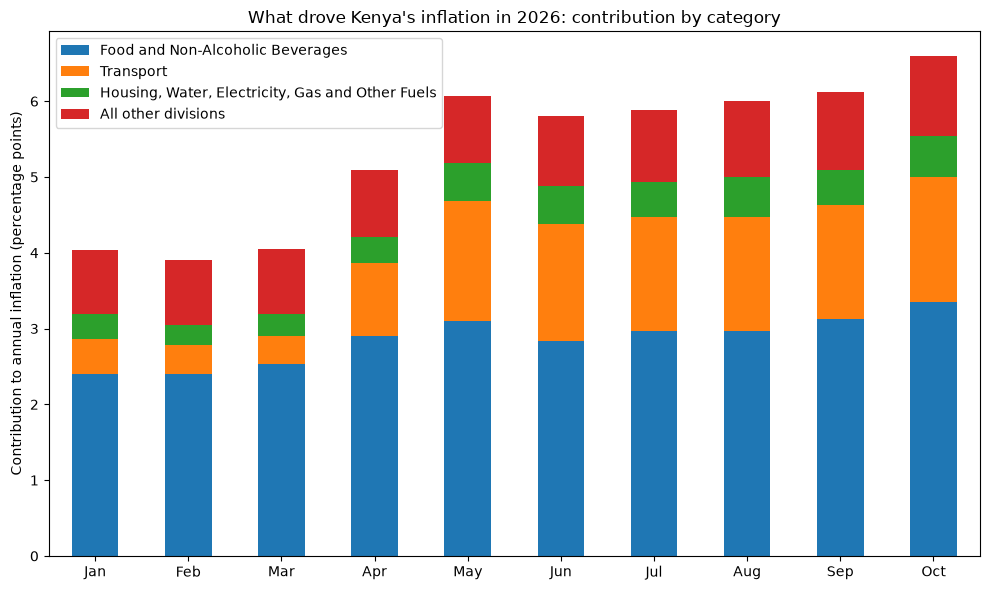

In [8]:
import matplotlib.pyplot as plt

top3 = ["Food and Non-Alcoholic Beverages", "Transport",
        "Housing, Water, Electricity, Gas and Other Fuels"]

div["group"] = div["division"].where(div["division"].isin(top3), "All other divisions")
pivot = (div.groupby(["month", "group"])["contribution"].sum()
            .unstack()[top3 + ["All other divisions"]])
pivot.index = pivot.index.strftime("%b")

ax = pivot.plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_title("What drove Kenya's inflation in 2026: contribution by category")
ax.set_ylabel("Contribution to annual inflation (percentage points)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(title="", loc="upper left")
plt.tight_layout()
plt.savefig("data/contributions_by_month.png", dpi=150)
plt.show()

In [9]:
t = cpi[cpi["division"] == "Transport"][["month", "monthly_change", "annual_change"]]
t["month"] = t["month"].dt.strftime("%b")
print(t.to_string(index=False))

month  monthly_change  annual_change
  Jan            -0.7            4.8
  Feb            -0.7            4.0
  Mar             0.0            3.8
  Apr             6.5           10.0
  May             6.1           16.5
  Jun             0.3           16.1
  Jul             0.3           15.6
  Aug             0.7           15.7
  Sep            -0.4           15.6
  Oct             1.7           17.1


In [10]:
import os
os.makedirs("data/data", exist_ok=True)
cpi.to_csv("data/data/cpi_divisions_2026.csv", index=False)
print(os.path.abspath("data/data/cpi_divisions_2026.csv"))
print(os.listdir("data/data"))

C:\Users\Antonette\OneDrive\Desktop\kenya-inflation-2026\data\data\cpi_divisions_2026.csv
['cpi_divisions_2026.csv']
